# TP3 — Grupo 1

**Integrantes:** Camila Ines Amado, Francisco Risculese, Agustin Macrina y Lucila Pasquetta

**Pregunta:** dado un precio de hotel en un contexto (lugar, fecha, ocupación), ¿es inusualmente bajo para su mercado?

El cálculo vive en el paquete `src/ofertas_hoteles/` y se corre con
`python -m ofertas_hoteles.pipeline`. Acá se muestran y se interpretan los resultados.


| Paso | Qué hace | Dónde |
|---|---|---|
| 1 | Muestra 2024 (train) y 2025, limpieza, mapeo de destinos, features | `data.py`, `mapping.py` |
| 2 | Set de validación y set de test (con casos controlados) | `testset.py` |
| 3 | 4 algoritmos principales (+ 4 variantes en el anexo) ajustados con 2024, umbral elegido en validación | `models.py`, `evaluate.py` |
| 4 | Métricas en test + análisis de errores | `evaluate.py`, `report.py` |
| 5 | Exportar el modelo final para la API | `pipeline.py`, `scorer.py`, `api.py` |
| 6 | Diagnósticos: cobertura del mapeo, representatividad de la muestra, 2024 vs 2025 | `diagnostics.py`, `estadistica.py` |

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import Image, display

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(PROJECT / "src"))
from ofertas_hoteles import config

# True = corre todo de cero (necesita data/datos_historicos_*.csv en la raíz del repo, ~1 min, ~1,1 GB de RAM)
CORRER_PIPELINE = False
if CORRER_PIPELINE:
    from ofertas_hoteles import pipeline
    sys.argv = ["pipeline"]
    pipeline.main()

OUT = config.OUTPUTS_DIR
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


## 0. Decisiones metodológicas 

| # | Decisión | Qué se hizo en este TP |
|---|---|---|
| 1 | **Unidad de análisis** | Una **búsqueda original** (una fila del CSV). No se expande a noches. |
| 2 | **Fuente de datos** | Ambos años: **2024 = entrenamiento**, **2025 = validación y test** (pools disjuntos). |
| 3 | **Muestreo** | 20% de cada año, aleatorio por chunks (`sample` en cada bloque), **semilla 42**. Representatividad verificada contra el total (sección 1.3). |
| 4 | **Fecha del contexto** | **Check-in** (`date_start`). |
| 5 | **Precio comparable** | `avg_price_average` = precio por **habitación-noche** (elasticidad a noches ≈ 0,05 y a habitaciones ≈ 0,02). La fórmula `/ (noches × habitaciones × personas)` se evalúa como sensibilidad (sección 6). |
| 6 | **Filtros de calidad** | noches, habitaciones y personas > 0; precio > 0; `date_end − date_start = nights`; check-in dentro del año del archivo (estos filtros no descartaron ninguna fila). **No se elimina ningún dato**: ni duplicados ni extremos. Extremos: **no se recortan**; se usan mediana/MAD y una regla de "sospechoso" (precio < 20% del típico). |
| 7 | **Mercado geográfico** | Destino canónico (cascada + `match_level`). Lo no mapeado queda con clave cruda `raw:país\|estado\|ciudad` (no se mezcla con canónicos ni entre países). Cobertura en sección 1.2. |
| 8 | **Desagregación temporal** | No se desagrega: la decisión es por consulta.|
| 9 | **Uso de `count_repeated`** | Referencias **sin ponderar** (cada búsqueda cuenta 1); métricas **ponderadas por demanda** como chequeo (sección 4.1) y cobertura del mapeo por demanda (1.2). |
| 10 | **Variables de segmentación** | Baseline: **destino × mes**. `price_bucket` solo como variante evaluada (descartada: el bucket depende del precio evaluado). Semana del mes descartada (en el TP2, el escenario con semana del mes dio igual que destino × mes). Ocupación y noches: solo diagnóstico de errores. |
| 11 | **Criterio de confianza** | **≥ 30 búsquedas** (registros, no demanda) en el contexto. Nivel usado → confianza alta (destino × mes), media (destino), baja (país). |
| 12 | **Fallbacks** | destino × mes → destino → país × mes → país → **sin soporte** (no decide). Probado en `tests/test_api.py`. |
| 13 | **Reproducibilidad** | `pip install -r requirements.txt && pip install -e .` → `python -m ofertas_hoteles.pipeline` → `pytest` → `jupyter nbconvert --execute`. |


## 1. Datos y decisiones

- **Unidad de análisis**: la búsqueda ya no se expande a noches: la decisión se toma por consulta,
  y la expansión repetía el mismo precio en varias filas (inflaba el soporte y creaba contextos sin dispersión).
  El contexto temporal es el **mes de check-in** (solo 5,8% de las estadías cruza de mes).
- **Precio comparable: `avg_price_average` tal cual (precio por habitación-noche).** Dentro de un mismo destino × mes,
  el precio casi no sube con las noches (elasticidad ≈ 0,05) ni con las habitaciones (≈ 0,02): ya viene por habitación
  y por noche. Dividirlo por noches × habitaciones × personas mete ruido (ver sección 6).
- **Mapeo de destinos:** la lógica de referencia (cascada de claves + `match_level`).
- **Sin eliminar datos:** se conservan todas las filas, incluidas las búsquedas repetidas y los precios extremos.

In [2]:
pd.read_csv(OUT / "resumen_datos.csv")

,anio,filas_muestra,filas_validas,filas_descartadas,repeticiones_exactas_conservadas,filas_checkin_otro_anio,filas_finales,pct_mapeado,pct_demanda_mapeada
0,2024,503564.0,503564.0,0.0,134.0,0.0,503564.0,68.74,80.99
1,2025,528074.0,528074.0,0.0,111.0,0.0,528074.0,69.24,79.88


**Lectura.** La tabla muestra cuántas filas se tomaron de cada año y cuántas quedaron para trabajar. **No se elimina ningún
dato:** los filtros de validez (noches, habitaciones y personas mayores a 0, precio positivo, fechas coherentes con la cantidad
de noches y check-in dentro del año) no descartaron ninguna fila (`filas_descartadas = 0`), así que las muestras quedan completas:
503.564 búsquedas de 2024 y 528.074 de 2025.

Tampoco se sacan las búsquedas repetidas. Hay 134 filas en 2024 y 111 en 2025 que repiten exactamente otra búsqueda (mismo lugar,
fechas, ocupación y precio). Se cuentan (`repeticiones_exactas_conservadas`) pero se dejan, porque son búsquedas que efectivamente
ocurrieron. Son tan pocas (0,03%) que no cambian las referencias de ningún mercado.

Los precios extremos también se conservan. En vez de recortarlos, el modelo usa estadísticos robustos (mediana y MAD) que no se
dejan arrastrar por ellos.


## 1.1 Qué cambia respecto del TP2 y por qué

Hay cinco decisiones que se revisaron con evidencia:

| Tema | TP2 | TP3 | Por qué |
|---|---|---|---|
| **Escenario de mercado** | B: destino × mes × `price_bucket` | **A: destino × mes** (B se sigue evaluando) | Usar `price_bucket` es una **limitación conocida, no un error**: el bucket se arma con el mismo precio que se evalúa, así que un precio rebajado puede pasar al bucket `low` y compararse con precios bajos. Se comparó directamente con y sin bucket en el mismo test: B detecta menos que A (recall 0,73 vs 0,76; anexo, sección 8). |
| **Unidad de análisis** | noche pagada (búsqueda expandida a noches) | **búsqueda** (fila original), contexto = mes de check-in | La decisión es por consulta; expandir repetía el mismo precio en varias filas e inflaba el soporte. |
| **Precio comparable** | `price_std` = precio / (noches × habitaciones × personas) | **`avg_price_average`** (precio por habitación-noche) | Dentro de destino × mes el precio casi no cambia con las noches (elasticidad 0,05) ni con las habitaciones (0,02): ya viene por habitación-noche. Dividir por noches × habitaciones × personas deja casi ciegos a los modelos (sección 6). Además, el código del repo, por un error, solo dividía el 5% de las filas: mezclaba dos unidades. |
| **Mapeo de destinos** | `apply_destination_mapping` del repo: 28–36% de match | **lógica de referencia**: 69% de filas / 81% de demanda | Corrige mayúsculas en `country_code`, claves de 2 partes, alias de EE.UU. y deja trazado `match_level`. |
| **`count_repeated`** | peso de demanda en los baselines | referencias sin ponderar (cada búsqueda cuenta 1) **+ métricas ponderadas por demanda como chequeo** (sección 4.1) | Se priorizó soporte = cantidad de búsquedas; la ponderación se usa para ver si el modelo rinde igual en las búsquedas más frecuentes. |



## 1.2 Cobertura del mapeo de destinos (dataset completo 2024 + 2025)

Se reporta: cobertura por filas, por demanda (`count_repeated`) y por geografías únicas,
cuántas filas resolvió cada regla (`match_level`) y las principales geografías no mapeadas por demanda.
Se calcula sobre **todo** el histórico, leído por chunks (paso 6 del pipeline).


In [3]:

D = OUT / "diagnosticos"
display(pd.read_csv(D / "cobertura_mapeo_resumen.csv").round(2))
display(pd.read_csv(D / "cobertura_mapeo_por_nivel.csv").round(2))
pd.read_csv(D / "cobertura_mapeo_no_mapeados_top.csv", keep_default_na=False).head(15)


,alcance,metrica,mapeado,total,cobertura_pct
0,2024+2025,filas,3558663,5158190,68.99
1,2024+2025,demanda (count_repeated),29916231,37167072,80.49
2,2024+2025,geografías únicas,14767,41535,35.55


,match_level,filas,demanda,geografias,pct_filas,pct_demanda
0,cc_state_code_city,1708954,17348126,6983,33.13,46.68
1,cc_country_city,1479587,10035493,5220,28.68,27.00
2,no_match,1599527,7250841,26768,31.01,19.51
3,cc_state_name_city,113200,1294177,26,2.19,3.48
4,non_us_state_as_place,228126,918793,2517,4.42,2.47
5,cc_usa_alias_state_code_city,16854,192935,3,0.33,0.52
6,cc_cdp_state_code_city,11942,126707,18,0.23,0.34


,country_code,country,state,city,row_count,demand_weight
0,us,United States of America,Florida,Miami Beach,19706,473159
1,us,United States of America,Nevada,Winchester,16900,386531
2,,,,,26649,373051
3,us,United States of America,California,Lomita Park,11188,279213
4,us,United States of America,Washington,SeaTac,8200,188259
5,us,United States of America,Florida,Dr. Phillips,14201,180182
6,us,United States of America,Puerto Rico,San Juan Antiguo,11875,168976
7,us,United States of America,Illinois,Norridge,8453,159172
8,nl,Netherlands,,,13494,113172
9,us,United States of America,Hawaii,Kahaluu-Keauhou CDP,9335,96614



**Lectura:** 69,0% de las filas y 80,5% de la demanda quedan mapeadas: coincide con la corrida de referencia.
Solo 35,6% de las geografías únicas se mapea porque hay una cola larga de barrios, CDP y localidades chicas con pocas filas.
El 31% de filas `no_match` (19,5% de la demanda) **no se descarta**: queda con su clave cruda y, si no tiene historial,
cae al fallback por país. Los principales no mapeados son zonas turísticas (Miami Beach, Winchester = Las Vegas Strip, SeaTac,
Dr. Phillips) y filas sin geografía; no se fuerzan fallbacks amplios para no generar falsos matches.



## 1.3 Representatividad de la muestra

Las conclusiones salen de una muestra del 20% de cada año, así que se compara con el **total** (filas válidas) en mes, país,
destino y distribución de precios.


In [4]:

display(pd.read_csv(D / "representatividad_resumen.csv").round(3))
display(pd.read_csv(D / "representatividad_precio.csv").round(2))
pd.read_csv(D / "representatividad_destino.csv").query("anio == 2025").head(10).round(3)


,anio,filas_validas_total,filas_muestra,fraccion_muestra_pct,max_dif_mes_pp,max_dif_pais_top15_pp,max_dif_destino_top20_pp,max_dif_cuantil_precio_pct
0,2024,2517822,503564,20.0,0.050,0.029,0.023,0.893
1,2025,2640368,528074,20.0,0.075,0.059,0.019,0.854


,anio,cuantil,total_aprox,muestra,dif_pct
0,2024,0.05,74.44,74.05,-0.53
1,2024,0.25,125.21,124.10,-0.89
2,2024,0.50,179.47,180.59,0.62
3,2024,0.75,284.29,286.83,0.89
4,2024,0.95,671.83,669.74,-0.31
5,2025,0.05,74.44,74.54,0.13
6,2025,0.25,120.30,120.33,0.02
7,2025,0.50,175.91,176.25,0.19
8,2025,0.75,284.29,284.37,0.03
9,2025,0.95,685.40,691.25,0.85


,destination_final,destino,pct_total,pct_muestra,dif_pp,anio
20,631,Cancun,1.710,1.728,0.018,2025
21,794,Punta Cana,1.616,1.631,0.015,2025
22,51051,Roppongi,1.585,1.577,-0.008,2025
23,684,Las Vegas,1.196,1.193,-0.003,2025
24,59070,Honolulu,1.148,1.148,-0.000,2025
25,797,Anaheim & Buena Park,0.975,0.971,-0.004,2025
26,645,Los Angeles,0.808,0.809,0.001,2025
27,663,Orlando,0.766,0.769,0.003,2025
28,raw:||,desconocido,0.746,0.743,-0.003,2025
29,660,Fort Lauderdale,0.729,0.720,-0.008,2025



**Lectura.** La muestra reproduce al total con diferencias **menores a 0,1 puntos porcentuales** en la participación de cada mes,
de los 15 países principales y de los 20 destinos principales, y menores a 1% en los cuantiles de precio (la comparación de
precios del total es aproximada, por histograma). Es decir, la muestra reproduce muy bien al total en meses, países, destinos y precios, así que las conclusiones sacadas de la muestra se pueden generalizar al dataset completo.



## 1.4 ¿2024 se parece a 2025? Homogeneidad entre años

El modelo aprende con 2024 y se prueba con 2025, así que conviene ver si los dos años son comparables mes a mes: cuántas búsquedas
hay, el precio mediano (global y **a igual destino**) y cómo le va al modelo en cada mes del test.

In [5]:
E = OUT / "estadistica"
hom = pd.read_csv(E / "homogeneidad_por_mes.csv")
hom.round(3)

,mes,busquedas_2024,busquedas_2025,mediana_2024,mediana_2025,razon_mediana_global,razon_mediana_mismo_destino,destinos_comparados,modelo_fpr_test,modelo_recall_test,modelo_alertas_reales
0,1,38754,37946,166.301,166.590,1.002,0.996,216,0.000,0.776,0.081
1,2,42998,39633,185.391,177.285,0.956,0.977,225,0.005,0.750,0.094
2,3,49272,46153,193.342,179.150,0.927,0.949,269,0.004,0.787,0.090
3,4,43547,44365,178.532,177.840,0.996,0.990,246,0.000,0.772,0.081
4,5,48852,47588,177.022,173.168,0.978,0.977,279,0.004,0.773,0.080
5,6,51102,49458,181.170,180.238,0.995,0.980,288,0.006,0.743,0.066
6,7,55162,53152,186.349,187.240,1.005,0.991,291,0.003,0.760,0.059
7,8,51361,48388,180.460,183.356,1.016,0.998,287,0.000,0.788,0.051
8,9,45036,43271,172.332,174.190,1.011,0.995,248,0.000,0.727,0.075
9,10,46433,45733,173.917,173.540,0.998,1.001,264,0.003,0.746,0.067


**Lectura.** De enero a octubre los dos años son muy parecidos. **Noviembre y diciembre de 2024 son distintos**: tienen muchas
menos búsquedas (21 mil y 10 mil contra 37 mil y 35 mil en 2025) y una mediana global mucho más alta (en diciembre, 228 contra
168 USD). Pero comparando **el mismo destino**, la razón de precios es ≈ 1,0 en esos meses: no cambiaron los precios, cambió
**qué destinos** se buscaron (efecto de composición).

Como el modelo compara contra el **mismo destino × mes**, ese cambio de composición casi no lo afecta: en el test los falsos
positivos de noviembre y diciembre son 0,1% y 0,5%, como en el resto del año. El costo real es que en esos meses hay **menos
historial** (solo 130 y 58 destinos comparables entre años), así que es esperable que más consultas caigan al fallback por destino o país. Queda como limitación:
**las referencias de noviembre y diciembre se apoyan en menos datos**.

## 2. Diseño del set de test

**Separación sin fugas**

- **Train = check-in 2024.** Es lo único que ven los modelos: referencias, cortes de `price_bucket`, Isolation Forest.
- **2025 se parte en tres pools que no se superponen** por grupo *destino × fecha de check-in* (una misma fecha-destino nunca cae en dos pools):
  - *mercado* (40%): solo sirve para armar la "verdad" (mediana de mercado 2025). Ningún modelo la ve.
  - *val* (30%): para elegir el umbral de cada modelo.
  - *test* (30%): se usa una sola vez, al final.
- **`price_bucket`** se calcula con cortes de train y se asigna sobre el **precio final** del caso (ya modificado),
  igual que pasaría en producción. Así no se mete un bucket "viejo" que no existiría en la realidad.

**Casos**

- **Controlados:** "anclas" = búsquedas reales con precio a ±10% de la mediana de mercado 2025 de su contexto (precios normales).
  A cada ancla se le aplican variaciones: −60%, −50%, −40%, −30% → *oferta clara* (1); −20%, −10% → *zona gris* (sin etiqueta);
  0%, +10%, +20%, +30%, +50% → *no oferta* (0); −90% → *error de carga* (se espera "sospechoso").
  Las anclas se estratifican por volumen del destino, trimestre y nivel de precio del mercado.
- **Reales:** 20.000 búsquedas al azar del pool, sin tocar, para medir cobertura y cuántas alertas daría el sistema.

 A continuación se mide cuántos casos hay en val y en test según distintas características: si el destino está mapeado, el nivel de precio del mercado, el trimestre, etc.

In [6]:
desc = pd.read_csv(OUT / "descripcion_sets.csv")
desc.pivot_table(index=["dimension", "valor"], columns="set", values="n").fillna(0).astype(int)

set                                      test    val
dimension            valor                          
is_mapped            False                824    587
                     True                2176   1413
nivel_precio_mercado barato               616    428
                     caro                 563    359
                     medio                586    400
                     muy_barato           679    425
                     muy_caro             556    388
nivel_verdad         destino             1111    782
                     destino_mes         1257    805
                     destino_trimestre    632    413
tier_destino         51-500              1104    675
                     cola                 830    549
                     nuevo_en_2025         18     19
                     poco_soporte_2024    139    137
                     top50                909    620
tipo                 error_carga         3000   2000
                     gris                6000   4000
                     no_oferta          15000  10000
                     oferta_clara       12000   8000
                     real               20000  20000
trimestre            T1                   732    487
                     T2                   762    504
                     T3                   777    519
                     T4                   729    490

In [7]:
test = pd.read_csv(config.DATA_DIR / "test_set.csv.gz", keep_default_na=False, na_values=[""])
test[["case_id", "tipo", "factor", "label", "destination_name", "date_start", "price_original", "price",
      "med_mercado_2025", "price_bucket_train", "tier_destino", "nivel_precio_mercado"]].sample(8, random_state=1)

,case_id,tipo,factor,label,destination_name,date_start,price_original,price,med_mercado_2025,price_bucket_train,tier_destino,nivel_precio_mercado
23814,test_2025_98944_f1.10,no_oferta,1.1,0.0,Chicago,2025-08-19,165.050000,181.555000,163.506833,high,top50,medio
47045,test_real_2025_107007,real,1.0,NaN,Fort Lauderdale,2025-06-05,127.740000,127.740000,152.260000,low,top50,medio
38859,test_real_2025_7160,real,1.0,NaN,Washington DC,2025-04-12,176.271000,176.271000,176.580450,medium,top50,medio
18143,test_2025_324560_f1.00,no_oferta,1.0,0.0,Oklahoma City,2025-03-04,86.839412,86.839412,92.409643,medium,51-500,muy_barato
12191,test_2025_4212_f0.80,gris,0.8,NaN,Asheville,2025-06-14,128.830000,103.064000,122.545714,low,51-500,barato
11597,test_2025_66940_f0.70,oferta_clara,0.7,1.0,Birmingham,2025-10-30,119.770000,83.839000,119.636667,low,51-500,barato
16611,test_2025_449518_f0.90,gris,0.9,NaN,Story,2025-09-08,208.360000,187.524000,229.030833,sin_cortes,poco_soporte_2024,caro
859,test_2025_128910_f0.40,oferta_clara,0.4,1.0,Flowers Bay,2025-01-12,169.563846,67.825538,177.796522,low,cola,medio


**Lectura:**

is_mapped: en test hay 824 anclas con destino no mapeado y 2.176 mapeadas (3.000 en total). En val hay 587 y 1.413 (2.000 en total). Proporcionalmente es parecido: ~27% vs ~29% sin mapear.

nivel_precio_mercado: cuántos casos hay de mercados baratos, caros, etc.

T1–T4: los trimestres. Se ve que hay casos de todo el año.

Nos interesa mostrar que val y test tienen una composición parecida y cubren todos los tipos de casos, gracias a la estratificación de las anclas.

## 3. Algoritmos comparados

Se comparan **cuatro algoritmos**:

| # | Algoritmo | Categoría | Idea | Umbral que se elige en validación |
|---|---|---|---|---|
| 1 | Aleatorio | baseline naive | marca oferta con probabilidad *p*, sin mirar el precio | *p* |
| 2 | Regla de mediana | baseline por regla simple | oferta si precio ≤ (1 − c) × mediana del contexto | *c* |
| 3 | **Propuesto (A)** | algoritmo del grupo | z robusto (mediana/MAD del log-precio) < corte **y** descuento ≥ 20% **y** no sospechoso (precio < 20% del típico) | *z_cut* |
| 4 | Isolation Forest | algoritmo (machine learning no supervisado) | bosque de aislamiento sobre desvío robusto, nivel de precio del contexto, noches, ocupación y mes; oferta = muy anómalo **y** debajo de la referencia | % más anómalo |

Todos usan el mismo **fallback**: destino × mes → destino → país × mes → país → *sin soporte* (no decide), con mínimo 30 búsquedas.

**Cómo se elige el umbral:** en validación, el de mayor F1 entre los que no marcan más del 10% de los precios reales como oferta (un detector que marca demasiado pierde valor como señal).

Además se probaron **otras cuatro variantes** (MAD puro, con `price_bucket`, la versión 1 (v1) con piso absoluto y el z-score del grupo). No entran en la comparación principal: se cuentan en el **anexo (sección 8)**.

In [8]:
PRINCIPALES = config.MODELOS_PRINCIPALES
PRINCIPALES

['1_aleatorio',
 '2_mediana_regla',
 '3_propuesto_robusto_A',
 '5_isolation_forest']

In [9]:
grid = pd.read_csv(OUT / "grilla_validacion.csv").query("modelo in @PRINCIPALES")
grid[["modelo", "param", "valor", "precision", "recall", "f1", "fpr", "tasa_alerta_reales", "elegido"]].round(3)

,modelo,param,valor,precision,recall,f1,fpr,tasa_alerta_reales,elegido
0,1_aleatorio,p,0.05,0.444,0.046,0.083,0.046,0.050,False
1,1_aleatorio,p,0.10,0.444,0.100,0.163,0.100,0.098,True
2,1_aleatorio,p,0.20,0.444,0.208,0.284,0.208,0.197,False
3,1_aleatorio,p,0.30,0.444,0.294,0.354,0.294,0.300,False
4,1_aleatorio,p,0.44,0.444,0.436,0.440,0.436,0.436,False
5,2_mediana_regla,c,0.10,0.879,0.981,0.928,0.108,0.395,False
6,2_mediana_regla,c,0.15,0.918,0.974,0.945,0.069,0.325,False
7,2_mediana_regla,c,0.20,0.943,0.956,0.950,0.046,0.262,False
8,2_mediana_regla,c,0.25,0.961,0.926,0.943,0.030,0.208,False
9,2_mediana_regla,c,0.30,0.972,0.867,0.916,0.020,0.160,False


---

<sub>**Nota.** La tabla muestra solo los cuatro modelos principales. Las otras cuatro variantes evaluadas (MAD puro, con `price_bucket`, versión 1 (v1) con piso absoluto y z-score del grupo) se filtran acá para no sobrecargar la comparación, y sus resultados se presentan en el anexo (sección 8). Por eso la numeración salta del modelo 3 al 5. Además, todos los modelos usan el mismo fallback (destino × mes → destino → país × mes → país → sin soporte, con mínimo 30 búsquedas), así que las diferencias de rendimiento se deben al método y no a los grupos de referencia.</sub>

**Lectura:** La tabla muestra, para cada modelo, cómo cambian las métricas al mover el umbral en validación. El umbral elegido (`elegido = True`) es el de mayor F1 entre los que marcan como máximo el 10% de los precios reales.

Con los umbrales elegidos:

| Modelo | Umbral | Precisión | Recall | F1 | FPR | Alertas en reales |
|---|---|---|---|---|---|---|
| 1. Aleatorio | p = 0,10 | 0,444 | 0,100 | 0,163 | 0,100 | 9,8% |
| 2. Mediana (regla) | c = 0,40 | 0,985 | 0,672 | 0,799 | 0,008 | 9,0% |
| **3. Propuesto robusto (A)** | **z = −1,50** | **0,992** | **0,752** | **0,856** | **0,005** | **7,5%** |
| 5. Isolation Forest | q = 0,20 | 0,886 | 0,384 | 0,536 | 0,040 | 10,0% |

- El **aleatorio** funciona como piso: su precisión es siempre 0,444, que es la proporción de ofertas en validación. Todos los modelos lo superan con claridad.
- El **propuesto robusto (A)** es el mejor en todas las métricas: encuentra 3 de cada 4 ofertas, casi no da falsas alarmas (0,5%) y genera menos alertas que el resto.
- La **regla de la mediana** queda cerca en precisión, pero encuentra menos ofertas (67% vs. 75%). La diferencia está en que el modelo robusto ajusta por la dispersión de precios de cada contexto (MAD), mientras que la regla usa el mismo porcentaje de descuento para todos.
- El **Isolation Forest** es el más débil de los modelos reales: detecta solo el 38% de las ofertas y da unas 8 veces más falsas alarmas que el robusto. Al buscar precios "raros" en general, sin compararlos con su contexto de mercado, le cuesta distinguir una oferta de un precio simplemente distinto.
- En todos los modelos se ve el mismo trade-off: un umbral más exigente sube la precisión y baja el recall. En el robusto, z = −1 detecta el 88% de las ofertas pero marca el 15,9% de los precios reales; z = −2,5 casi no se equivoca pero detecta solo el 45%.

Estos resultados son de **validación** y sirven para fijar los umbrales. La comparación final se hace en test (sección 4).



## 4. Métricas elegidas y resultados en test

**Subconjunto de métricas y por qué:**

- **Precisión** — de lo que mostramos como oferta, cuánto lo es. Es la que más cuida la confianza del usuario.
- **Recall** — de las ofertas claras, cuántas encontramos. Sin esto, un detector que no marca nada parece perfecto.
- **F1** — resume el equilibrio entre las dos para comparar y elegir umbral.
- **Tasa de falsos positivos (FPR)** — de los precios normales o caros, cuántos marcamos mal. Es independiente de cuántas ofertas
  pusimos en el test, a diferencia de la precisión.
- **Cobertura** — en cuántos casos el sistema puede decidir. Un modelo que se abstiene mucho puede tener buena precisión "haciendo trampa".
- **Tasa de alerta en reales** y **errores de carga marcados como oferta** — métricas operativas: cuánto ruido daría en producción y si
  recomendaría precios que son claramente errores.
- **Accuracy se reporta pero no se usa para decidir:** depende de la proporción de positivos que elegimos al diseñar el test.

Los casos *sin soporte* cuentan como "no oferta" (es lo que vería el usuario). Los intervalos de confianza se calculan re-muestreando **anclas** (las 12 variantes de un mismo precio salen juntas), para no subestimar la incertidumbre.

In [10]:
m_all = pd.read_csv(OUT / "metricas_test.csv")
m = m_all[m_all["modelo"].isin(PRINCIPALES)]
cols = ["modelo", "param", "valor", "accuracy", "precision", "recall", "f1", "fpr", "cobertura", "cobertura_reales",
        "tasa_alerta_reales", "error_carga_como_oferta", "f1_ic95"]
m[cols].sort_values("f1", ascending=False).round(3)

,modelo,param,valor,accuracy,precision,recall,f1,fpr,cobertura,cobertura_reales,tasa_alerta_reales,error_carga_como_oferta,f1_ic95
2,3_propuesto_robusto_A,z_cut,-1.5,0.891,0.996,0.758,0.861,0.003,1.0,0.998,0.076,0.004,"[0.853, 0.867]"
1,2_mediana_regla,c,0.4,0.850,0.989,0.670,0.798,0.006,1.0,0.998,0.087,1.000,"[0.793, 0.804]"
6,5_isolation_forest,q,0.2,0.710,0.892,0.395,0.548,0.038,1.0,0.998,0.102,0.658,"[0.532, 0.562]"
0,1_aleatorio,p,0.1,0.544,0.444,0.102,0.166,0.102,1.0,1.000,0.097,0.102,"[0.152, 0.181]"



### 4.1 Chequeo ponderado por demanda (`count_repeated`)

Mismas métricas, pero cada caso pesa según cuántas veces se repitió esa búsqueda (las variantes de un ancla
heredan su peso). Responde: ¿el modelo funciona igual de bien en las búsquedas que más se hacen?


In [11]:
w = pd.read_csv(OUT / "metricas_test_ponderadas.csv")
comp = m[["modelo", "precision", "recall", "f1", "fpr", "tasa_alerta_reales"]].merge(w, on="modelo")
comp[["modelo", "precision", "precision_pond", "recall", "recall_pond", "f1", "f1_pond",
      "fpr", "fpr_pond", "tasa_alerta_reales", "tasa_alerta_reales_pond"]].sort_values("f1_pond", ascending=False).round(3)

,modelo,precision,precision_pond,recall,recall_pond,f1,f1_pond,fpr,fpr_pond,tasa_alerta_reales,tasa_alerta_reales_pond
2,3_propuesto_robusto_A,0.996,0.998,0.758,0.806,0.861,0.892,0.003,0.001,0.076,0.045
1,2_mediana_regla,0.989,0.996,0.670,0.686,0.798,0.812,0.006,0.002,0.087,0.044
3,5_isolation_forest,0.892,0.906,0.395,0.301,0.548,0.452,0.038,0.025,0.102,0.047
0,1_aleatorio,0.444,0.444,0.102,0.112,0.166,0.178,0.102,0.112,0.097,0.090



**Lectura:** vemos que el ranking no cambia. Ponderando por demanda, el propuesto sube a F1 0,89 (recall 0,81) y marca 4,5% de las búsquedas reales: rinde **mejor** en los destinos y fechas más buscados, que son los que tienen más historial.
Isolation Forest empeora (F1 0,45): sus aciertos se concentran en búsquedas poco frecuentes.


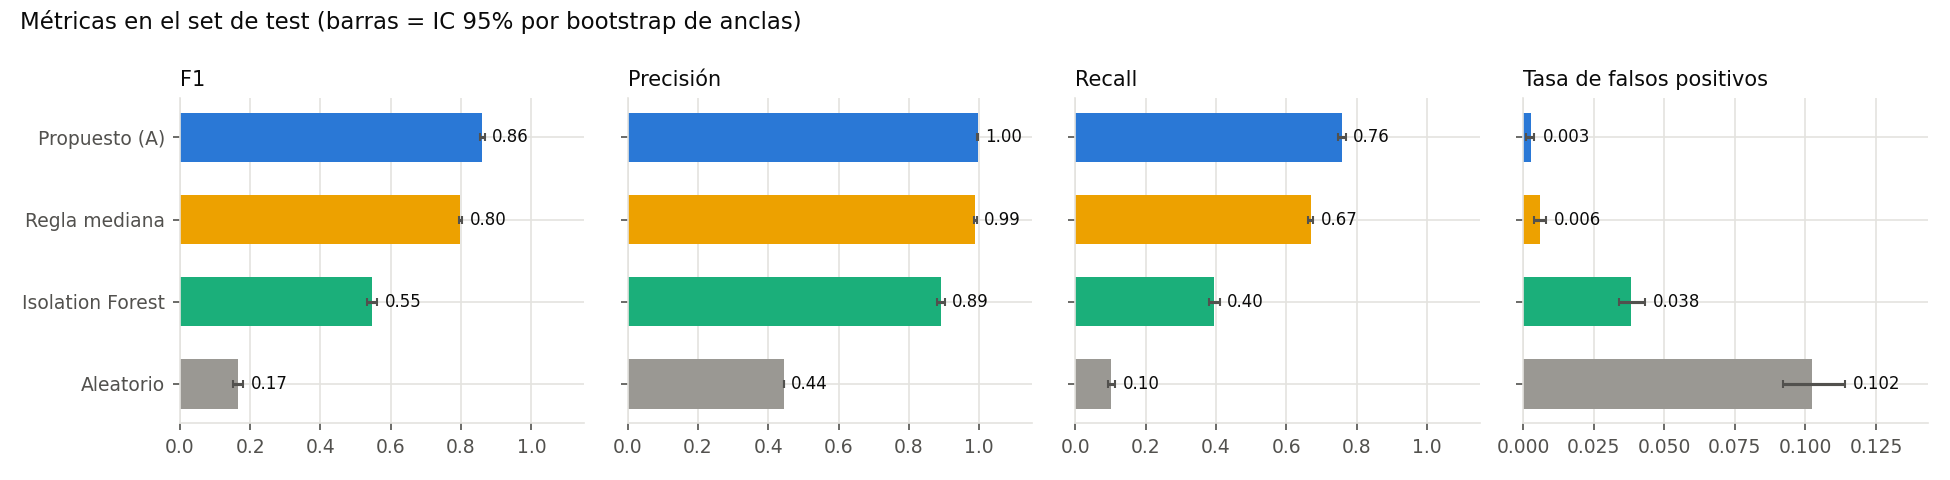

In [12]:
display(Image(OUT / "figuras" / "metricas_test.png"))

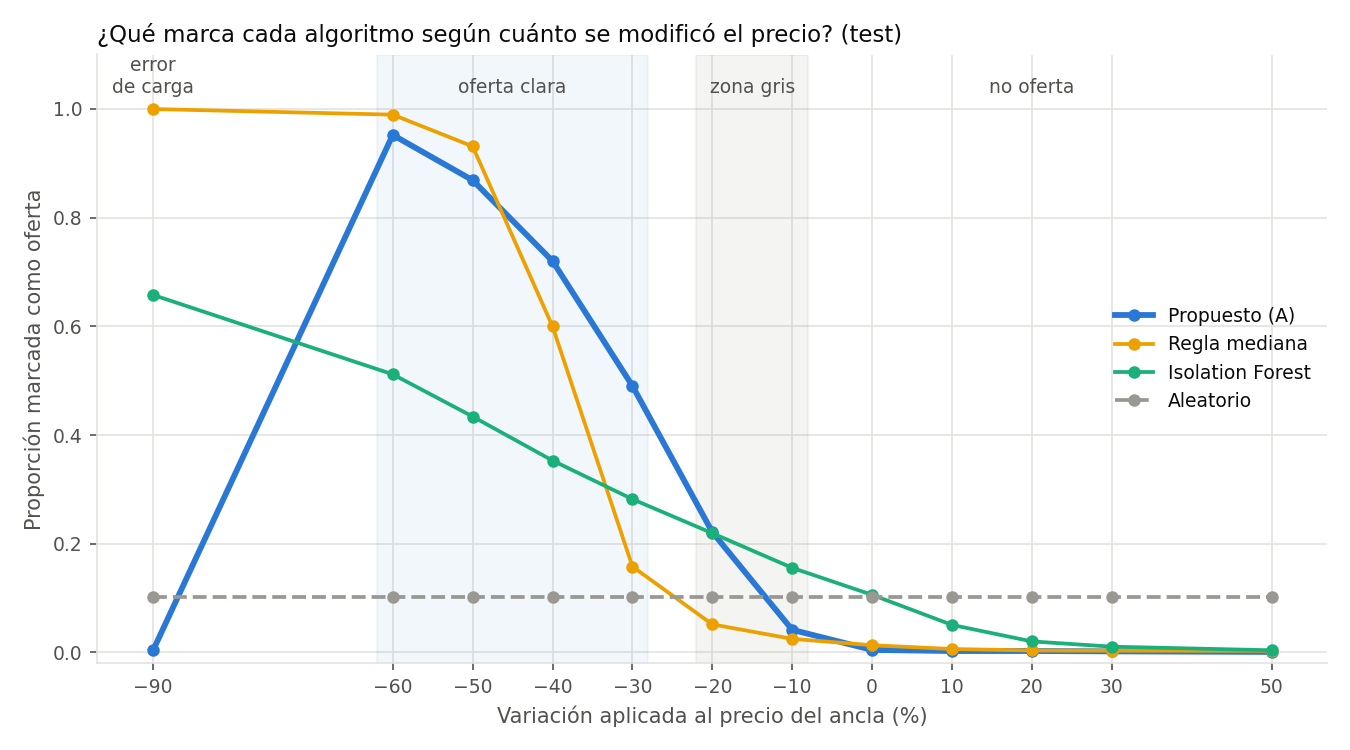

In [13]:
display(Image(OUT / "figuras" / "curva_deteccion.png"))

**Lectura**

- **Aleatorio** marca el piso: F1 0,17. Cualquier algoritmo útil tiene que estar muy por encima.
- **La regla de mediana es fuerte** (F1 0,80, precisión 0,99), pero detecta casi todo a −50% y casi nada
  a −30%, porque no sabe cuánto varían los precios en cada mercado. Además marca como oferta el **100%** de los errores de carga (−90%).
- **El propuesto A es el mejor** (F1 0,86, precisión 0,996, FPR 0,3%): al medir el desvío en "variaciones típicas" de cada mercado detecta más que la regla (recall 0,76 vs 0,67) sin más falsas alarmas, y separa los errores de carga como *sospechosos* (solo 0,4% llega como oferta).
- **Isolation Forest es el más flojo de los tres no aleatorios** (F1 0,55, FPR 3,8%): busca casos *raros*, y "raro" no es lo mismo que "barato". Marca combinaciones poco comunes (estadías de 8+ noches, ocupaciones raras) aunque el precio sea normal.

## 5. Análisis de errores: ¿dónde falla el modelo elegido?

In [14]:
e_all = pd.read_csv(OUT / "errores_por_segmento.csv")
e = e_all[e_all["modelo"].isin(["2_mediana_regla", "3_propuesto_robusto_A", "5_isolation_forest"])]
def tabla(dim):
    x = e[e["dimension"] == dim]
    return x.pivot(index="segmento", columns="modelo", values=["recall", "fpr"]).round(3)
tabla("nivel_precio_mercado")

recall                                                      fpr                                         
modelo     2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest 2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest
segmento                                                                                                                    
barato               0.717                 0.884              0.381           0.004                 0.002              0.030
caro                 0.616                 0.634              0.242           0.002                 0.001              0.020
medio                0.656                 0.754              0.293           0.001                 0.001              0.025
muy_barato           0.733                 0.908              0.600           0.019                 0.007              0.056
muy_caro             0.607                 0.564              0.424           0.001                 0.000              0.058

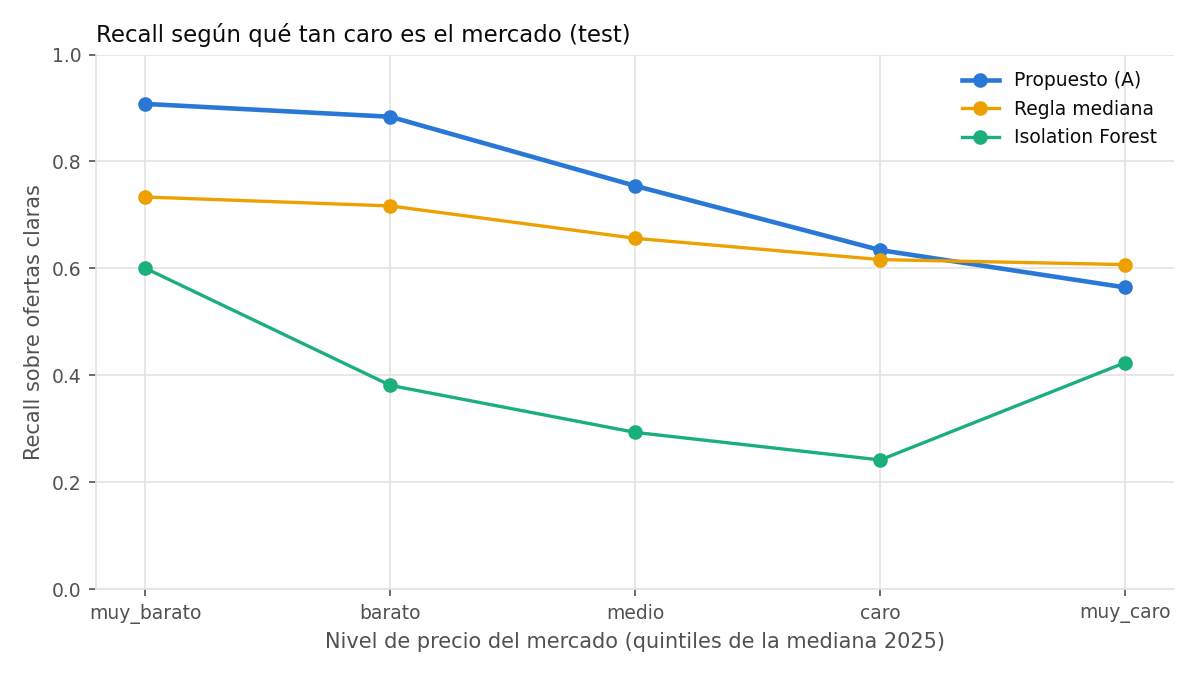

In [15]:
display(Image(OUT / "figuras" / "recall_por_nivel_precio.png"))

In [16]:
tabla("nivel_contexto")

recall                                                      fpr                                         
modelo      2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest 2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest
segmento                                                                                                                     
destino               0.645                 0.710              0.335           0.002                 0.000              0.036
destino_mes           0.675                 0.802              0.450           0.001                 0.002              0.036
pais_mes              0.782                 0.616              0.231           0.087                 0.028              0.083

In [17]:
tabla("tier_destino")

recall                                                      fpr                                         
modelo            2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest 2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest
segmento                                                                                                                           
51-500                      0.678                 0.803              0.395           0.003                 0.003              0.034
cola                        0.628                 0.688              0.287           0.001                 0.000              0.027
nuevo_en_2025               0.361                 0.292              0.125           0.000                 0.000              0.033
poco_soporte_2024           0.836                 0.658              0.245           0.098                 0.032              0.089
top50                       0.677                 0.791              0.522           0.000                 0.000              0.046

In [18]:
tabla("noches")

recall                                                      fpr                                         
modelo   2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest 2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest
segmento                                                                                                                  
1                  0.688                 0.814              0.498           0.006                 0.003              0.035
2-3                0.667                 0.759              0.300           0.006                 0.002              0.030
4-7                0.652                 0.703              0.367           0.006                 0.003              0.036
8+                 0.684                 0.742              0.790           0.008                 0.005              0.138

In [19]:
tabla("ocupacion")

recall                                                      fpr                                         
modelo     2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest 2_mediana_regla 3_propuesto_robusto_A 5_isolation_forest
segmento                                                                                                                    
1_pax_hab            0.708                 0.815              0.731           0.005                 0.001              0.063
2_pax_hab            0.669                 0.757              0.264           0.006                 0.003              0.024
3+_pax_hab           0.645                 0.722              0.551           0.005                 0.002              0.062

**Dónde falla el modelo propuesto**

Análisis de errores del modelo propuesto: en qué situaciones al modelo propuesto (el robusto A) le va peor y por qué. Nos muestra cuáles son las limitaciones del modelo.

1. Descuentos del 30%: detecta solo la mitad

El modelo marca oferta cuando el precio está 1,5 desvíos robustos (MAD × 1,4826) por debajo de la mediana de su contexto, en logaritmo. En un destino × mes típico, eso equivale a estar más o menos 33% por debajo. Entonces un descuento del 30% queda justo en el límite: a veces lo pasa y a veces no.

El modelo tampoco detecta “este hotel bajó su precio”, detecta “este precio es bajo comparado con el mercado”. Un hotel caro con 30% de descuento puede seguir siendo un precio normal para su zona. Para el modelo eso no es oferta, y es coherente con cómo se definió el problema.


2. Mercados caros: detecta menos

En destinos caros conviven hoteles de 3 y de 5 estrellas, así que los precios están muy dispersos. Cuando la dispersión es grande, la MAD es grande, y un descuento queda “dentro de lo normal”. Por ejemplo, si en un destino hay hoteles de 150 a 600, un 5 estrellas que baja de 600 a 420 sigue estando en el rango.

La solución sería comparar cada hotel con otros de su misma categoría, pero el dataset no tiene estrellas. Es una limitación de los datos, no del método.

3. Fallback a país: peor rendimiento

Cuando no hay datos del destino, se compara contra el país entero, y eso es muy grueso: un hotel en Bariloche comparado con todo Argentina. Detecta menos ofertas (recall 0,62) y da muchas más falsas alarmas: 2,8% contra 0,2% en el nivel destino × mes, unas 16 veces más.

**Por eso la API avisa con confianza = baja: el usuario sabe que ese resultado es menos confiable.**

4. Destinos nuevos o con poco historial en 2024

Si un destino casi no aparece en 2024, el modelo no aprendió cuánto cuesta ahí. Son pocos casos, pero ahí el modelo funciona peor (detecta entre 29% y 66%).

5. Ocupación: con 3+ personas detecta menos

Una habitación para 3 o 4 personas cuesta más que una para 1. La elasticidad de 0,32 quiere decir que el precio sube con la cantidad de personas: al duplicar personas, sube cerca de 25%. Pero el contexto (destino × mes) no separa por cantidad de personas. Entonces una habitación para 4 con descuento puede quedar en un precio que parece normal, porque el modelo la compara con habitaciones de 1 o 2 personas, que son más baratas.

Esto conecta con lo que vimos antes: el precio comparable es por habitación-noche, no por persona. Ahí aparece el costo de esa decisión.

En resumen

El modelo funciona bien cuando el contexto es específico y homogéneo, y empeora cuando el grupo de comparación mezcla cosas distintas: hoteles de distinta categoría, un país entero o distintas ocupaciones.

## 6. Sensibilidad a la unidad de precio

Misma corrida completa pero con la fórmula `avg_price_average / (noches × habitaciones × personas)`:

In [20]:
s = pd.read_csv(OUT / "sensibilidad_unidad_precio" / "metricas_test_formula_alternativa.csv").query("modelo in @PRINCIPALES")
display(s[["modelo", "valor", "precision", "recall", "f1", "fpr", "tasa_alerta_reales"]].round(3))
display(pd.read_csv(OUT / "sensibilidad_unidad_precio" / "dispersion_por_unidad.csv").round(3))
display(pd.read_csv(OUT / "sensibilidad_unidad_precio" / "elasticidades_avg_price_average.csv").round(3))

,modelo,valor,precision,recall,f1,fpr,tasa_alerta_reales
0,1_aleatorio,0.10,0.444,0.103,0.167,0.103,0.097
1,2_mediana_regla,0.40,0.984,0.641,0.776,0.008,0.280
2,3_propuesto_robusto_A,-1.25,0.999,0.165,0.283,0.000,0.079
6,5_isolation_forest,0.10,0.810,0.044,0.084,0.008,0.082


,unidad,contextos_destino_mes,mad_log_mediano,descuento_minimo_detectable_z-1.5
0,habitacion_noche,3371,0.179,0.329
1,formula_alternativa,3371,0.542,0.700
2,codigo_repo,3371,0.189,0.343


,variable,elasticidad_log_precio
0,noches,0.055
1,habitaciones,0.020
2,personas,0.323


**Lectura.** Esta sección repite toda la evaluación cambiando solo la unidad de precio: en vez de usar `avg_price_average` como precio por habitación-noche, se usa la fórmula `avg_price_average / (noches × habitaciones × personas)`. El objetivo es ver si las conclusiones dependen de esa decisión.

**El resultado cambia mucho.** Con la fórmula alternativa, todos los modelos pierden capacidad de detección:

| Modelo | Umbral | Precisión | Recall | F1 | FPR | Alertas en reales |
|---|---|---|---|---|---|---|
| 1. Aleatorio | p = 0,10 | 0,444 | 0,103 | 0,167 | 0,103 | 9,7% |
| 2. Mediana (regla) | c = 0,40 | 0,984 | 0,641 | 0,776 | 0,008 | 28,0% |
| 3. Propuesto robusto (A) | z = −1,25 | 0,999 | 0,165 | 0,283 | 0,000 | 7,9% |
| 5. Isolation Forest | q = 0,10 | 0,810 | 0,044 | 0,084 | 0,008 | 8,2% |

El modelo propuesto, que era el mejor con la unidad habitación-noche, pasa a detectar solo el 17% de las ofertas (F1 = 0,283 frente a 0,861 en la versión principal). Sigue sin dar falsas alarmas, pero casi no encuentra nada.

**Por qué pasa.** La fórmula alternativa aumenta mucho la dispersión de los precios dentro de cada contexto:

- Con habitación-noche, la MAD mediana del log-precio en destino × mes es 0,179, y el descuento mínimo que el modelo puede detectar (con z < −1,5) es de alrededor del 33%.
- Con la fórmula alternativa, la MAD sube a 0,542 (tres veces más), y el descuento mínimo detectable pasa a ser del 70%. Una oferta del 30% o 40% queda escondida dentro de la variación normal.

Las elasticidades explican de dónde sale esa dispersión. El precio casi no depende de la cantidad de noches (0,055) ni de habitaciones (0,020), es decir, suponemos que ya viene expresado por habitación-noche. Dividir otra vez por esas cantidades no corrige nada: agrega variación artificial. Con las personas pasa algo parecido: el precio sí sube con la ocupación (0,323), pero mucho menos que proporcionalmente, así que dividir por personas sobrecorrige.

**Conclusión.** Las conclusiones son sensibles a la unidad de precio, y la evidencia respalda usar habitación-noche como unidad principal. La fórmula alternativa no mejora la comparabilidad: la empeora, porque divide el precio por cantidades de las que casi no depende.

**Nota sobre el TP2.** El código del repo que aplicaba esa fórmula (`standardize_prices`), por un error, solo dividía el
**5% de las filas** (las que tenían 2 o más noches **y** 2 o más habitaciones); el resto quedaba sin dividir. O sea que en la
práctica mezclaba dos unidades de precio. En la tabla de dispersión de arriba, esa mezcla (`codigo_repo`) apenas sube la MAD (0,189 vs 0,179) porque
afecta a pocas filas, pero los precios de esas filas quedan en otra escala. Esto refuerza la decisión de usar **una sola unidad, sin dividir**, en todo el
pipeline.


### 6.1 ¿Mezclar estadías de distinta duración sesga la comparación?

Se usa `avg_price_average` sin dividir como única unidad en todo el pipeline (referencias, validación, test y API): nunca se
normaliza dos veces. Para no comparar estadías de duraciones distintas, cada búsqueda conserva `nights` y se verificó si separar
por cantidad de noches cambia los resultados: mismo modelo, pero con contexto **destino × mes × grupo de noches**
(1 / 2–3 / 4–6 / 7+) y fallback a destino × mes → destino → país. Mismo train, umbral elegido en validación y mismo test
(`scripts/sensibilidad_noches.py`).

In [21]:
S = OUT / "sensibilidad_noches"
display(pd.read_csv(S / "precio_por_grupo_noches.csv").round(1))
display(pd.read_csv(S / "metricas_test_contexto_noches.csv")[
    ["modelo", "precision", "recall", "f1", "f1_ic95", "fpr", "tasa_alerta_reales", "pct_anclas_nivel_noches"]].round(3))
display(pd.read_csv(S / "metricas_por_grupo_noches.csv").pivot(index="noches", columns="modelo", values="f1").round(3))

,noches,dif_pct_vs_destino_mes,pct_busquedas
0,1,-1.1,26.2
1,2-3,0.0,40.2
2,4-6,0.6,23.7
3,7+,0.0,10.0


,modelo,precision,recall,f1,f1_ic95,fpr,tasa_alerta_reales,pct_anclas_nivel_noches
0,3_propuesto_robusto_A,0.996,0.758,0.861,"[0.853, 0.867]",0.003,0.076,0.000
1,3e_propuesto_noches,0.995,0.760,0.862,"[0.854, 0.869]",0.003,0.078,32.733


modelo,3_propuesto_robusto_A,3e_propuesto_noches
noches,,
1,0.896,0.884
2-3,0.862,0.863
4-6,0.831,0.846
7+,0.821,0.832


**Lectura.** Dentro de un mismo destino × mes, el precio por noche casi no cambia con la duración
(menos de 1,1% entre grupos): el precio ya está por noche y las duraciones son comparables. Separar el contexto por noches
da el mismo resultado (F1 0,862 vs 0,861, intervalos superpuestos) y solo un tercio de los casos tiene historial suficiente
para usar ese nivel. Se mantiene **destino × mes**, más simple y con más soporte por contexto.

## 7. Decisión final

**Se elige el propuesto (A): z robusto mediana/MAD por destino × mes, descuento mínimo 20%, filtro relativo de errores de carga y fallback jerárquico hasta país.** Umbral `z_cut = −1,5` (elegido en validación).

- Es el de mejor F1 de la comparación (0,86) y detecta más que la regla de mediana (recall 0,76 vs 0,67) con mayor precisión (0,996 vs 0,989) y menos falsos positivos (0,3% vs 0,6%).
- De los cuatro, es el único que **no recomienda errores de carga** como ofertas.
- Marca ~8% de los precios reales: selectivo pero útil.
- Es interpretable ("41% por debajo del típico de su mercado") y liviano: la API solo necesita tablas de referencia.
- Las variantes del anexo confirman cada pieza del diseño: sin las reglas detecta igual pero recomienda errores; con `price_bucket`
  o con piso absoluto detecta menos.

**Política: priorizar precisión sobre recall (decisión explícita).** El umbral `z_cut = −1,5` hace que el modelo casi nunca
marque como oferta un precio normal (precisión 0,996, 0,3% de falsos positivos, 0,2% de los precios con +30% marcados), a costa
de no ver las rebajas chicas: detecta 49% de las de −30% y 22% de las de −20%. El descuento mínimo que detecta de forma
confiable ronda el **33%**. Se eligió así porque recomendar como oferta algo que no lo es hace perder la confianza del usuario.
Si el producto necesitara encontrar más ofertas, el mismo modelo con `z_cut = −1,0` detecta 88% en validación, pero marca
16% de los precios reales como oferta (deja de ser una señal selectiva).

**Fallback validado:** cobertura 99,8% de los precios reales; lo que no tiene soporte responde `sin_soporte` sin romper
(probado en `tests/test_api.py`), y cada respuesta trae `nivel_contexto`, `confianza`, cuántas búsquedas sostienen la referencia (`n_referencia`) y cuánta demanda representan (`demanda_referencia`, suma de `count_repeated`), además de las `noches` de la consulta para trazar el contexto. La API responde `oferta: SI / NO`.

## 8. Anexo: otros modelos que se probaron

Además de los cuatro principales se probaron cuatro variantes. Casi todas son **el propuesto con una pieza cambiada**: sirven para
mostrar qué aporta cada decisión de diseño (lo que se llama *análisis de ablación*). Se evaluaron con el mismo test y el mismo criterio
de umbral, pero **no compiten** por la elección final.

| Variante | Qué le cambia al propuesto | F1 | Recall | FPR | Errores de carga → oferta | Qué muestra |
|---|---|---|---|---|---|---|
| **MAD puro** | le saca el descuento mínimo y el filtro de errores | 0,863 | 0,762 | 0,4% | **100%** | detecta igual: el núcleo es el mismo z robusto. **Las reglas de negocio son las que evitan recomendar errores** |
| **Con `price_bucket` (B)** | agrega la gama de precio al contexto | 0,844 | 0,733 | 0,3% | 1,6% | detecta menos: el bucket depende del precio que se evalúa, así que una rebaja puede cambiar de gama. Es una **limitación declarada** de B, no un error; por eso se eligió A |
| **v1 (piso absoluto)** | marca "sospechoso" todo precio < p1 global (≈ 44 USD) | 0,809 | 0,681 | 0,3% | 0,4% | castiga a los mercados baratos (recall 0,58 en "muy barato" vs 0,91 sin el piso) |
| **z-score del grupo** | media y desvío en vez de mediana y MAD; contexto semana × bucket | 0,839 | 0,731 | 0,9% | 94,7% | detecta algo menos y da el triple de falsos positivos; no tiene filtro de errores (marca como oferta el 95% de los errores de carga), la media y el desvío se dejan arrastrar por los extremos y el contexto fino deja 14% de los precios reales sin decidir: **por qué usar estadística robusta** |

In [22]:
m_all[~m_all["modelo"].isin(PRINCIPALES)][["modelo", "valor", "precision", "recall", "f1", "fpr", "cobertura_reales",
                                            "error_carga_como_oferta", "f1_ic95"]].sort_values("f1", ascending=False).round(3)

,modelo,valor,precision,recall,f1,fpr,cobertura_reales,error_carga_como_oferta,f1_ic95
5,4_mad_puro,-1.5,0.994,0.762,0.863,0.004,0.998,1.000,"[0.855, 0.870]"
4,3b_propuesto_robusto_B,-1.5,0.994,0.733,0.844,0.003,0.998,0.016,"[0.836, 0.851]"
7,6_zscore_grupo,-1.0,0.985,0.731,0.839,0.009,0.862,0.947,"[0.831, 0.847]"
3,3c_propuesto_v1_piso_abs,-1.5,0.995,0.681,0.809,0.003,0.998,0.004,"[0.800, 0.817]"
